# Lecture-Theatre Evacuation: The Faster-Is-Slower Effect and a Door Obstacle

### Summary
This notebook lays the groundwork for simulating pedestrian evacuation dynamics within a structured, tiered lecture theatre. It compiles and validates the global parameters, establishes a high-fidelity coordinates layout representing seating blocks and aisles, and implements optimized Numba physical interaction forces for both particle-particle and particle-wall boundaries. Finally, it validates these implementations against fundamental mechanical truths, including Newton's Third Law (force reciprocity), sliding friction vector direction opposition, and frictional coefficient dependence.

In [39]:
# Setup Cell - Installs, Imports, and Parameter Definition

!pip install -q numba

import sys
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import numba
from numba import njit

BASE_SEED = 42
rng = np.random.default_rng(BASE_SEED)

print(f"Python Version: {sys.version}")
print(f"NumPy Version: {np.__version__}")
print(f"Matplotlib Version: {matplotlib.__version__}")
print(f"Numba Version: {numba.__version__}")

PARAMS = {
    'm': 80.0,              # Pedestrian mass [kg]
    'r_min': 0.25,          # Minimum body radius [m]
    'r_max': 0.35,          # Maximum body radius [m] (uniform random body radius)
    'tau': 0.5,             # Relaxation time [s]
    'A': 2000.0,            # Social interaction force strength [N]
    'B': 0.08,              # Social interaction force range [m]
    'k': 1.2e5,             # Body compression force constant [N/m]
    'kappa': 2.4e5,         # Sliding friction force constant [kg/(m*s)]
    'dt_trial': 0.01,       # Trial time step [s], final value chosen from convergence study
    'v0': 1.5,              # Desired speed [m/s]

    # Real Geometry Parameters
    'seat_pitch': 0.75,     # Spacing between seat centres along a row [m]
    'seats_per_row': 15,    # Number of seats per row
    'rows': 10,             # Number of seating rows
    'row_depth': 0.9,       # Back-to-front depth of a row space [m]
    'aisle_width': 1.2,     # Main corridor width [m]
    'front_depth': 3.0,     # Depth of front area near exit [m]
    'exit_width': 1.2,      # Width of the exit door [m]
    'obstacle_radius': 0.3, # Obstacle radius [m]
    'obstacle_dist': 1.5,   # Obstacle distance from exit [m]
    'n_aisles': 2,          # Number of aisles inside room
    'block_seats': 5        # Number of seats per row block
}

# Enforce consistency check
assert PARAMS['seats_per_row'] == (PARAMS['n_aisles'] + 1) * PARAMS['block_seats'], "Geometry block parameters inconsistent!"
print("Setup parameters compiled and validated.")

Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
NumPy Version: 2.4.6
Matplotlib Version: 3.10.0
Numba Version: 0.64.0
Setup parameters compiled and validated.


## 1. Problem and question

### Real-World Situation
During an emergency evacuation in a structured, tiered lecture theatre, occupants must navigate through highly constrained architectural corridors (such as aisles and rows of fixed seating) to reach a single narrow exit. As urgency levels rise, panic can lead to dense crowding, physical crushing, and friction-driven structural blockages near the exit.

### Central Scientific Question
*Does a higher desired speed slow down the overall evacuation time, and can placing a rigid structural obstacle immediately upstream of the exit gate improve outflow?*

### Practical Importance
Answering this allows architects and safety designers to construct non-intuitive safety interventions (like pillars or structural dividers) that may reduce crushing risk.

### Scope and Assumptions
- Pedestrians are simulated as two-dimensional physical disks moving in a bounded geometry.
- Group behaviors, leadership, panic-induced injuries, and impatience are excluded.
- The lecture theatre is physically tiered, but our model is a 2D plan-view representation and ignores the slope.
- Occupants possess complete knowledge of the room layout and navigate toward designated exit waypoints.

## 2. Model, assumptions and equations

### Key Model Assumptions
1. Pedestrians move within a 2D plane ($x, y$) without vertical variance, ignoring physical steps or slopes.
2. Every pedestrian has a constant mass but body radius is assigned as a uniform random variable in [0.25, 0.35] m representing soft-contact discs.
3. Each agent maintains a constant target desired speed $v_0$ throughout the simulation run.
4. Seat backs are modelled as walls, so each row is a narrow lane and people leave it sideways toward an aisle.

### Governing Mathematical Equations

The acceleration of agent $i$ is determined by Newton's Second Law:
$$m_i \frac{d\mathbf{v}_i}{dt} = \mathbf{f}_i^{\text{des}} + \sum_{j \neq i} \mathbf{f}_{ij} + \sum_{w} \mathbf{f}_{iw}$$

#### 1. Desired Force
$$\mathbf{f}_i^{\text{des}} = m_i \frac{v_0 \mathbf{e}_i(t) - \mathbf{v}_i(t)}{\tau}$$
Where $\mathbf{e}_i(t)$ is the unit vector pointing toward the agent's target waypoint, and $\tau$ is the velocity relaxation time.

#### 2. Pair Interaction Force (Social + Physical Contact)
$$\mathbf{f}_{ij} = \left[ A \exp\left( \frac{r_{ij} - d_{ij}}{B} \right) + k g(r_{ij} - d_{ij}) \right] \mathbf{n}_{ij} + \kappa g(r_{ij} - d_{ij}) (\Delta v_{ji} \cdot \mathbf{t}_{ij}) \mathbf{t}_{ij}$$
Where:
- $r_{ij} = r_i + r_j$ is the sum of radii, and $d_{ij} = \|\mathbf{x}_i - \mathbf{x}_j\|$ is the center-to-center distance.
- $\mathbf{n}_{ij} = (\mathbf{x}_i - \mathbf{x}_j)/d_{ij}$ is the normal direction pointing from $j$ to $i$.
- $\mathbf{t}_{ij} = (-n_{ij,y}, n_{ij,x})$ is the tangent direction.
- $g(x) = \max(0, x)$ is a ramp function activated only upon physical compression overlap.
- $\Delta v_{ji} = (\mathbf{v}_j - \mathbf{v}_i)$ represents relative sliding velocity.

#### 3. Wall Interaction Force
$$\mathbf{f}_{iw} = \left[ A \exp\left( \frac{r_i - d_{iw}}{B} \right) + k g(r_i - d_{iw}) \right] \mathbf{n}_{iw} - \kappa g(r_i - d_{iw}) (\mathbf{v}_i \cdot \mathbf{t}_{iw}) \mathbf{t}_{iw}$$
Where:
- $d_{iw}$ is the distance from the center of person $i$ to the nearest point on the wall segment.
- $\mathbf{n}_{iw}$ is the unit vector pointing from that nearest point toward the person.
- $\mathbf{t}_{iw} = (-n_{iw,y}, n_{iw,x})$ is the unit tangent direction.
- Circular obstacles (pillars) are handled with an identical physical structure, where $d_{iw}$ is calculated as the radial distance from the agent center to the boundary of the physical pillar circle.

### Parameter Summary Table
| Symbol | Parameter Description | Standard Value | Unit | Source / Assumption |
|:---:|:---|:---:|:---:|:---|
| $m$ | Pedestrian mass | 80 | kg | Helbing et al. (2000) |
| $r$ | Pedestrian radius | random uniform [0.25, 0.35] | m | Assumed to capture variance |
| $\tau$ | Relaxation time | 0.5 | s | Helbing et al. (2000) |
| $A$ | Social force magnitude | 2000 | N | Helbing et al. (2000) |
| $B$ | Social force range | 0.08 | m | Helbing et al. (2000) |
| $k$ | Elastic compression constant | $1.2 \times 10^5$ | N/m | Helbing et al. (2000) |
| $\kappa$ | Sliding friction constant | $2.4 \times 10^5$ | kg/(m s) | Helbing et al. (2000) |
| $v_0$ | Desired speed | 1.5 default; swept 1.0 to 5.0 | m/s | Helbing et al. (2000) / Sweep range |
| $\Delta t$ | Simulation time step | To be determined | s | Chosen via convergence study |
| - | Aisle width | 1.2 | m | Assumed |
| - | Front depth | 3.0 | m | Assumed |
| - | Exit width | 1.2 | m | Assumed |
| - | Obstacle radius | 0.3 | m | Assumed |
| - | Obstacle distance | 1.5 | m | Assumed |

### Integration Scheme
We utilize the **Velocity Verlet** time-integration scheme to advance trajectories. Since forces depend on velocity, $\mathbf{a}_i(t+\Delta t)$ is computed using a predicted velocity $\mathbf{v}_i^* = \mathbf{v}_i(t) + \mathbf{a}_i(t)\Delta t$. The order of accuracy will be measured in the time-step study rather than assumed beforehand:
$$\mathbf{x}_i(t+\Delta t) = \mathbf{x}_i(t) + \mathbf{v}_i(t)\Delta t + \frac{1}{2}\mathbf{a}_i(t)\Delta t^2$$
$$\mathbf{v}_i(t+\Delta t) = \mathbf{v}_i(t) + \frac{\mathbf{a}_i(t) + \mathbf{a}_i(t+\Delta t)}{2}\Delta t$$

### Concepts Used
- Particle-based classical mechanics
- Numerical ODE solvers (Velocity Verlet)
- Spatial Partitioning (Grid Cell Lists)
- Monte Carlo replications & Law of Large Numbers
- Random variate generation (body radii, seat occupancy)

## 3. Implementation

In [40]:
# 3.1 Geometry Builder
# modified to use dynamic parameters

def build_room_geometry(params):
    """
    Coordinate System:
    - x-axis: across the room width (0 to room_w).
    - y-axis: measured back from the front wall (y = 0 is the exit wall).
    """
    rows = int(params['rows'])
    seat_pitch = params['seat_pitch']
    row_depth = params['row_depth']
    aisle_width = params['aisle_width']
    front_depth = params['front_depth']
    exit_width = params['exit_width']
    n_aisles = int(params['n_aisles'])
    block_seats = int(params['block_seats'])

    num_blocks = n_aisles + 1
    block_w = block_seats * seat_pitch
    room_w = (num_blocks * block_w) + (n_aisles * aisle_width)
    room_l = (rows * row_depth) + front_depth

    walls = []

    # Left and right boundary walls
    walls.append([0.0, 0.0, 0.0, room_l])
    walls.append([room_w, 0.0, room_w, room_l])

    # Back wall
    walls.append([0.0, room_l, room_w, room_l])

    # Front wall (at y=0) with exit gap
    mid_x = room_w / 2.0
    half_exit = exit_width / 2.0
    walls.append([0.0, 0.0, mid_x - half_exit, 0.0])
    walls.append([mid_x + half_exit, 0.0, room_w, 0.0])

    # Seat-back lane walls representing boundaries for rows
    for r in range(rows):
        y_pos = front_depth + (r * row_depth)
        for b in range(num_blocks):
            b_left = b * (block_w + aisle_width)
            b_right = b_left + block_w
            walls.append([b_left, y_pos, b_right, y_pos])

    exit_line = np.array([mid_x - half_exit, 0.0, mid_x + half_exit, 0.0])
    return np.array(walls, dtype=np.float64), exit_line

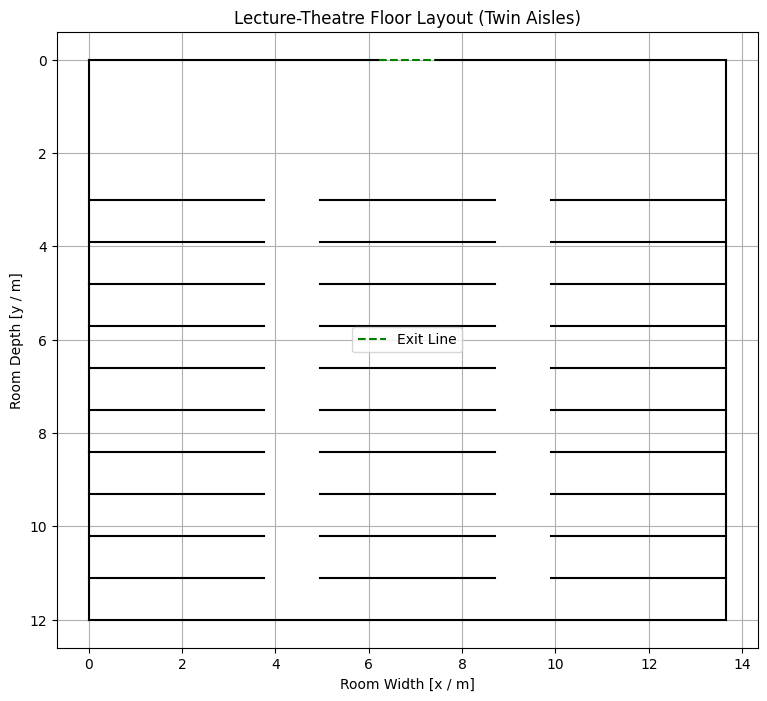

In [41]:
# 3.2 Floor Layout Visual Validation
#  modified to add aspect ratio scaling
import matplotlib.pyplot as plt

walls, exit_line = build_room_geometry(PARAMS)
fig = plt.figure(figsize=(10, 8))
for w in walls:
    plt.plot([w[0], w[2]], [w[1], w[3]], 'k-')
plt.plot([exit_line[0], exit_line[2]], [exit_line[1], exit_line[3]], 'g--', label='Exit Line')
plt.title("Lecture-Theatre Floor Layout (Twin Aisles)")
plt.xlabel("Room Width [x / m]")
plt.ylabel("Room Depth [y / m]")
plt.gca().invert_yaxis()
plt.gca().set_aspect('equal')
plt.legend()
plt.grid(True)
plt.show()

In [42]:
# 3.3 Dynamic Interaction Force Core


@njit
def compute_pair_force_scalar(dr, dv, r_i, r_j, A, B, k, kappa):
    """
    Calculates normal interaction and tangential friction force component.
    dr = x_i - x_j [m]
    dv = v_i - v_j [m/s]
    """
    dist = np.sqrt(dr[0]**2 + dr[1]**2)
    if dist == 0.0:
        return np.zeros(2)

    n = dr / dist
    t = np.array([-n[1], n[0]])

    overlap = (r_i + r_j) - dist
    f_mag = A * np.exp(overlap / B)

    if overlap > 0.0:
        f_mag += k * overlap
        f_friction = -kappa * overlap * np.dot(dv, t) * t
    else:
        f_friction = np.zeros(2)

    return f_mag * n + f_friction

@njit
def compute_wall_force_scalar(x_i, v_i, r_i, w_seg, A, B, k, kappa):
    p1 = w_seg[0:2]
    p2 = w_seg[2:4]
    line_vec = p2 - p1
    line_len = np.sqrt(line_vec[0]**2 + line_vec[1]**2)
    if line_len == 0.0:
        return np.zeros(2)
    t_wall = line_vec / line_len

    proj = np.dot(x_i - p1, t_wall)
    proj_clamped = max(0.0, min(line_len, proj))
    closest_pt = p1 + proj_clamped * t_wall

    dr = x_i - closest_pt
    d_iw = np.sqrt(dr[0]**2 + dr[1]**2)
    if d_iw == 0.0:
        return np.zeros(2)

    n_iw = dr / d_iw
    t_iw = np.array([-n_iw[1], n_iw[0]])

    overlap = r_i - d_iw
    f_mag = A * np.exp(overlap / B)

    if overlap > 0.0:
        f_mag += k * overlap
        f_friction = -kappa * overlap * np.dot(v_i, t_iw) * t_iw
    else:
        f_friction = np.zeros(2)

    return f_mag * n_iw + f_friction

In [43]:
#3.4  Agent placement, room constants and numerical settings
import time

def place_agents(params, rng, jitter=0.02):
    """All seats occupied. Random body radius (uniform) and a small random offset inside the seat [m].
    Seat centres: pitch along x, row-lane centre along y."""
    rows = int(params['rows']); num_blocks = int(params['n_aisles']) + 1; bs = int(params['block_seats'])
    pitch, rd, aw, fd = params['seat_pitch'], params['row_depth'], params['aisle_width'], params['front_depth']
    block_w = bs * pitch
    pos = []
    for r in range(rows):
        y = fd + (r + 0.5) * rd
        for b in range(num_blocks):
            b_left = b * (block_w + aw)
            for s in range(bs):
                pos.append([b_left + (s + 0.5) * pitch, y])
    pos = np.array(pos, dtype=np.float64)
    pos += rng.uniform(-jitter, jitter, pos.shape)               # random offset inside the seat
    rad = rng.uniform(params['r_min'], params['r_max'], len(pos))  # random body radius
    return pos, rad

def aisle_centres(params):
    bs, pitch, aw = int(params['block_seats']), params['seat_pitch'], params['aisle_width']
    block_w = bs * pitch
    return np.array([(a + 1) * block_w + a * aw + aw / 2.0 for a in range(int(params['n_aisles']))])

walls, exit_line = build_room_geometry(PARAMS)
AISLE_XC = aisle_centres(PARAMS)
ROOM_W = float(walls[:, 0].max())          # x extent [m]
ROOM_L = float(walls[:, 3].max())          # y extent [m]
EXIT_X = 0.5 * (exit_line[0] + exit_line[2])

D_CUT = 2.0          # pair-force cutoff on centre distance [m] (checked in 4.5)
WALL_CUT = 1.5       # wall-force cutoff on centre-to-wall distance [m] (checked in 4.5)
TURN_ZONE = 1.2      # within this distance of an aisle centre line, agents head diagonally into the aisle [m]
DT = 0.001           # trial time step [s]; 0.002 let agents tunnel through walls at v0 >= 7 m/s. Final value: convergence study.
NX = int(ROOM_W / D_CUT) + 1
NY = int(ROOM_L / D_CUT) + 1

# parameter vectors for the numba kernels: [m, tau, A, B, k, kappa, d_cut, wall_cut]
P_VEC = np.array([PARAMS['m'], PARAMS['tau'], PARAMS['A'], PARAMS['B'], PARAMS['k'], PARAMS['kappa'], D_CUT, WALL_CUT])
GEO = np.array([PARAMS['front_depth'], EXIT_X, -1.0, TURN_ZONE])   # [front_depth, exit_x, exit_target_y, turn_zone]

pos_demo, rad_demo = place_agents(PARAMS, np.random.default_rng(BASE_SEED))
print(f"{len(pos_demo)} agents placed; room {ROOM_W:.2f} m x {ROOM_L:.2f} m; aisle centres {AISLE_XC}")


150 agents placed; room 13.65 m x 12.00 m; aisle centres [4.35 9.3 ]


In [44]:
#3.5  Desired direction (waypoint rule)
@njit
def desired_direction(x, y, aisle_xc, front_depth, exit_x, exit_y, turn_zone):
    """Unit vector toward the current target.
    Front area (y < front_depth): head for the exit.
    Seating zone: head for the nearest aisle. Within turn_zone of the aisle centre line the target is
    1 m ahead toward the front, so agents leave the row diagonally and then walk down the aisle.
    (A pure sideways target made people from opposite sides block each other head-on at the aisle entrance.)"""
    if y < front_depth:
        tx, ty = exit_x, exit_y
    else:
        best = 0
        bd = abs(x - aisle_xc[0])
        for a in range(1, len(aisle_xc)):
            d = abs(x - aisle_xc[a])
            if d < bd:
                bd = d
                best = a
        tx = aisle_xc[best]
        if bd < turn_zone:
            ty = y - 1.0
        else:
            ty = y
    dx, dy = tx - x, ty - y
    d = np.sqrt(dx * dx + dy * dy)
    if d == 0.0:
        return 0.0, 0.0
    return dx / d, dy / d

In [45]:
# 3.6a  Reference neighbour search and wall loop (slow, uses the verified scalar kernels from 3.3)
@njit
def pair_forces_brute_ref(pos, vel, rad, active, A, B, k, kappa, d_cut, F):
    """Brute-force O(N^2) pair forces with a distance cutoff. Reference for the cell-list check."""
    n = len(pos)
    F[:, :] = 0.0
    cut2 = d_cut * d_cut
    for i in range(n):
        if not active[i]:
            continue
        for j in range(i + 1, n):
            if not active[j]:
                continue
            dr = pos[i] - pos[j]
            if dr[0] * dr[0] + dr[1] * dr[1] > cut2:
                continue
            f = compute_pair_force_scalar(dr, vel[i] - vel[j], rad[i], rad[j], A, B, k, kappa)
            F[i] += f
            F[j] -= f      # Newton's third law

@njit
def wall_forces_ref(pos, vel, rad, active, walls, A, B, k, kappa, wall_cut, F):
    F[:, :] = 0.0
    cut2 = wall_cut * wall_cut
    for i in range(len(pos)):
        if not active[i]:
            continue
        x, y = pos[i, 0], pos[i, 1]
        for w in range(len(walls)):
            dx = max(min(walls[w, 0], walls[w, 2]) - x, 0.0, x - max(walls[w, 0], walls[w, 2]))
            dy = max(min(walls[w, 1], walls[w, 3]) - y, 0.0, y - max(walls[w, 1], walls[w, 3]))
            if dx * dx + dy * dy > cut2:
                continue
            F[i] += compute_wall_force_scalar(pos[i], vel[i], rad[i], walls[w], A, B, k, kappa)


In [46]:
 #3.6b  Fast kernels (no array allocation) and cell-list neighbour search
@njit
def pair_force_fast(drx, dry, dvx, dvy, ri, rj, A, B, k, kappa):
    """Same formula as compute_pair_force_scalar, written with scalars only. dr = x_i - x_j, dv = v_i - v_j."""
    dist = np.sqrt(drx * drx + dry * dry)
    if dist == 0.0:
        return 0.0, 0.0
    nx = drx / dist; ny = dry / dist
    tx = -ny; ty = nx
    ov = ri + rj - dist
    fm = A * np.exp(ov / B)
    if ov > 0.0:
        fm += k * ov
        fr = -kappa * ov * (dvx * tx + dvy * ty)
        return fm * nx + fr * tx, fm * ny + fr * ty
    return fm * nx, fm * ny

@njit
def wall_force_fast(x, y, vx, vy, r, x1, y1, x2, y2, A, B, k, kappa):
    """Same formula as compute_wall_force_scalar, scalars only."""
    lx = x2 - x1; ly = y2 - y1
    L = np.sqrt(lx * lx + ly * ly)
    if L == 0.0:
        return 0.0, 0.0
    twx = lx / L; twy = ly / L
    proj = (x - x1) * twx + (y - y1) * twy
    proj = max(0.0, min(L, proj))
    cx = x1 + proj * twx; cy = y1 + proj * twy
    drx = x - cx; dry = y - cy
    d = np.sqrt(drx * drx + dry * dry)
    if d == 0.0:
        return 0.0, 0.0
    nx = drx / d; ny = dry / d
    tx = -ny; ty = nx
    ov = r - d
    fm = A * np.exp(ov / B)
    if ov > 0.0:
        fm += k * ov
        fr = -kappa * ov * (vx * tx + vy * ty)
        return fm * nx + fr * tx, fm * ny + fr * ty
    return fm * nx, fm * ny

@njit
def pair_forces_brute_fast(pos, vel, rad, active, A, B, k, kappa, d_cut, F):
    n = len(pos)
    F[:, :] = 0.0
    cut2 = d_cut * d_cut
    for i in range(n):
        if not active[i]:
            continue
        for j in range(i + 1, n):
            if not active[j]:
                continue
            drx = pos[i, 0] - pos[j, 0]; dry = pos[i, 1] - pos[j, 1]
            if drx * drx + dry * dry > cut2:
                continue
            fx, fy = pair_force_fast(drx, dry, vel[i, 0] - vel[j, 0], vel[i, 1] - vel[j, 1], rad[i], rad[j], A, B, k, kappa)
            F[i, 0] += fx; F[i, 1] += fy
            F[j, 0] -= fx; F[j, 1] -= fy

@njit
def pair_forces_cells(pos, vel, rad, active, A, B, k, kappa, d_cut, nx, ny, head, nxt, F):
    """Cell-list pair forces. The room is cut into square cells of side d_cut, so every neighbour within
    d_cut lies in the same or one of the 8 adjacent cells. head[c] = first agent in cell c, nxt[i] = next one."""
    n = len(pos)
    F[:, :] = 0.0
    head[:] = -1
    cut2 = d_cut * d_cut
    for i in range(n):                       # build the linked lists
        if active[i]:
            cx = min(nx - 1, max(0, int(pos[i, 0] / d_cut)))
            cy = min(ny - 1, max(0, int(pos[i, 1] / d_cut)))
            c = cy * nx + cx
            nxt[i] = head[c]
            head[c] = i
    for i in range(n):                       # search the 3x3 block of cells around each agent
        if not active[i]:
            continue
        cx = min(nx - 1, max(0, int(pos[i, 0] / d_cut)))
        cy = min(ny - 1, max(0, int(pos[i, 1] / d_cut)))
        for ddx in range(-1, 2):
            for ddy in range(-1, 2):
                ncx = cx + ddx; ncy = cy + ddy
                if ncx < 0 or ncx >= nx or ncy < 0 or ncy >= ny:
                    continue
                j = head[ncy * nx + ncx]
                while j != -1:
                    if j > i:                # each pair once
                        drx = pos[i, 0] - pos[j, 0]; dry = pos[i, 1] - pos[j, 1]
                        if drx * drx + dry * dry <= cut2:
                            fx, fy = pair_force_fast(drx, dry, vel[i, 0] - vel[j, 0], vel[i, 1] - vel[j, 1], rad[i], rad[j], A, B, k, kappa)
                            F[i, 0] += fx; F[i, 1] += fy
                            F[j, 0] -= fx; F[j, 1] -= fy
                    j = nxt[j]

@njit
def wall_forces_fast(pos, vel, rad, active, walls, A, B, k, kappa, wall_cut, F):
    """Adds wall forces to F (does not zero it). Walls farther than wall_cut are skipped by a bounding-box test."""
    cut2 = wall_cut * wall_cut
    for i in range(len(pos)):
        if not active[i]:
            continue
        x = pos[i, 0]; y = pos[i, 1]
        for w in range(len(walls)):
            x1 = walls[w, 0]; y1 = walls[w, 1]; x2 = walls[w, 2]; y2 = walls[w, 3]
            dx = max(min(x1, x2) - x, 0.0, x - max(x1, x2))
            dy = max(min(y1, y2) - y, 0.0, y - max(y1, y2))
            if dx * dx + dy * dy > cut2:
                continue
            fx, fy = wall_force_fast(x, y, vel[i, 0], vel[i, 1], rad[i], x1, y1, x2, y2, A, B, k, kappa)
            F[i, 0] += fx; F[i, 1] += fy


In [47]:
#3.6c  Circular pillar: force from a circular obstacle (same force law as the walls, computed once on the circle)
@njit
def circle_force_fast(x, y, vx, vy, r, cx, cy, R, A, B, k, kappa):
    """Force on an agent (centre x,y; radius r) from a circular pillar (centre cx,cy; radius R).
    d = distance from the agent centre to the pillar SURFACE; same form as the wall force (Eq. 3)."""
    drx = x - cx; dry = y - cy
    dc = np.sqrt(drx * drx + dry * dry)
    if dc == 0.0:
        return 0.0, 0.0
    d = dc - R
    nx = drx / dc; ny = dry / dc
    tx = -ny; ty = nx
    ov = r - d
    fm = A * np.exp(ov / B)
    if ov > 0.0:
        fm += k * ov
        fr = -kappa * ov * (vx * tx + vy * ty)
        return fm * nx + fr * tx, fm * ny + fr * ty
    return fm * nx, fm * ny

@njit
def obstacle_forces_fast(pos, vel, rad, active, obst, A, B, k, kappa, cut, F):
    """Adds the forces of all circular pillars (rows of obst: cx, cy, R) to F."""
    for i in range(len(pos)):
        if not active[i]:
            continue
        for o in range(len(obst)):
            dx = pos[i, 0] - obst[o, 0]; dy = pos[i, 1] - obst[o, 1]
            if np.sqrt(dx * dx + dy * dy) - obst[o, 2] > cut:
                continue
            fx, fy = circle_force_fast(pos[i, 0], pos[i, 1], vel[i, 0], vel[i, 1], rad[i],
                                       obst[o, 0], obst[o, 1], obst[o, 2], A, B, k, kappa)
            F[i, 0] += fx; F[i, 1] += fy


In [48]:
#3.7  Acceleration, main time loop (velocity Verlet) and a run wrapper

@njit
def accel_fast(pos, vel, rad, active, v0, walls, obst, aisle_xc, geo, P, use_cells, nx, ny, head, nxt, F, acc):
    m, tau, A, B, k, kappa, d_cut, wall_cut = P[0], P[1], P[2], P[3], P[4], P[5], P[6], P[7]
    front_depth, exit_x, exit_y, turn_zone = geo[0], geo[1], geo[2], geo[3]
    if use_cells:
        pair_forces_cells(pos, vel, rad, active, A, B, k, kappa, d_cut, nx, ny, head, nxt, F)
    else:
        pair_forces_brute_fast(pos, vel, rad, active, A, B, k, kappa, d_cut, F)
    wall_forces_fast(pos, vel, rad, active, walls, A, B, k, kappa, wall_cut, F)
    obstacle_forces_fast(pos, vel, rad, active, obst, A, B, k, kappa, wall_cut, F)
    for i in range(len(pos)):
        if active[i]:
            ex, ey = desired_direction(pos[i, 0], pos[i, 1], aisle_xc, front_depth, exit_x, exit_y, turn_zone)
            acc[i, 0] = (m * (v0 * ex - vel[i, 0]) / tau + F[i, 0]) / m
            acc[i, 1] = (m * (v0 * ey - vel[i, 1]) / tau + F[i, 1]) / m
        else:
            acc[i, 0] = 0.0
            acc[i, 1] = 0.0

@njit
def run_core_fast(pos0, rad, v0, dt, T_max, walls, obst, aisle_xc, geo, P, use_cells, nx, ny, rec_every):
    """Velocity Verlet for the whole crowd. An agent is removed when its centre crosses y = 0 (the exit line).
    Returns exit times, people-out history, conservation flag, steps done, final pos, vel, active flags."""
    n = len(pos0)
    pos = pos0.copy()
    vel = np.zeros_like(pos)
    active = np.ones(n, dtype=np.bool_)
    t_exit = np.full(n, np.nan)
    F = np.zeros_like(pos); acc = np.zeros_like(pos); acc_new = np.zeros_like(pos)
    head = np.full(nx * ny, -1, dtype=np.int64); nxt = np.full(n, -1, dtype=np.int64)
    max_steps = int(T_max / dt)
    out_hist = np.zeros(max_steps // rec_every + 2, dtype=np.int64)
    n_rec = 0; n_out = 0; cons_ok = True
    accel_fast(pos, vel, rad, active, v0, walls, obst, aisle_xc, geo, P, use_cells, nx, ny, head, nxt, F, acc)
    steps_done = 0
    for step in range(max_steps):
        t = (step + 1) * dt
        pos_new = pos + vel * dt + 0.5 * acc * dt * dt          # position update
        v_pred = vel + acc * dt                                   # predicted velocity (forces depend on velocity)
        accel_fast(pos_new, v_pred, rad, active, v0, walls, obst, aisle_xc, geo, P, use_cells, nx, ny, head, nxt, F, acc_new)
        vel = vel + 0.5 * (acc + acc_new) * dt                    # velocity update
        pos = pos_new
        acc = acc_new.copy()
        n_active = 0
        for i in range(n):
            if active[i]:
                if pos[i, 1] < 0.0:                               # crossed the exit line
                    active[i] = False
                    t_exit[i] = t
                    n_out += 1
                    vel[i, 0] = 0.0; vel[i, 1] = 0.0; acc[i, 0] = 0.0; acc[i, 1] = 0.0
                else:
                    n_active += 1
        if n_active + n_out != n:                                 # conservation of people
            cons_ok = False
        if step % rec_every == 0:
            out_hist[n_rec] = n_out
            n_rec += 1
        steps_done = step + 1
        if n_out == n:
            break
    return t_exit, out_hist[:n_rec], cons_ok, steps_done, pos, vel, active

NO_OBST = np.zeros((0, 3))      # no pillar

def run_evacuation(v0, seed, dt=DT, T_max=400.0, use_cells=True, rec_every=100, pos0=None, rad=None, obst=None):
    """One evacuation run. Returns a dict. evac_time is NaN if not everybody left within T_max
    or if any agent ended outside the room (tunnelling through a wall)."""
    obst = NO_OBST if obst is None else obst
    if pos0 is None:
        pos0, rad = place_agents(PARAMS, np.random.default_rng(seed))
    t_exit, hist, cons, steps, pos_end, vel_end, active = run_core_fast(
        pos0, rad, v0, dt, T_max, walls, obst, AISLE_XC, GEO, P_VEC, use_cells, NX, NY, rec_every)
    outside = active & ((pos_end[:, 0] < 0) | (pos_end[:, 0] > ROOM_W) | (pos_end[:, 1] > ROOM_L))
    all_out = not active.any()
    ok = all_out and cons and not outside.any()
    return dict(evac_time=(np.nanmax(t_exit) if ok else np.nan), n_out=int((~active).sum()), conserved=cons,
                tunnelled=int(outside.sum()), steps=steps, t_exit=t_exit, out_hist=hist,
                pos_end=pos_end, vel_end=vel_end, active=active)

_ = run_evacuation(PARAMS['v0'], BASE_SEED, T_max=1.0)    # compile once
print("Crowd simulation compiled.")



Crowd simulation compiled.


In [49]:
#3.8  Replications, 95% confidence intervals, time-step rule and a parallel batch runner
from scipy import stats
from numba import prange

def dt_for_speed(v0):
    """Time step [s] as a function of desired speed. Chosen from the time-step study (cells 4.9, 4.10):
    0.002 s let agents tunnel through walls at v0 = 10 m/s, 0.001 s still lost 1 run in 12, 0.0005 s was clean."""
    return 0.001 if v0 <= 5.0 else 0.0005

def mean_ci(x, level=0.95):
    """Mean and half-width of the two-sided confidence interval (Student t, because the number of seeds is small)."""
    x = np.asarray(x, dtype=float)
    n = len(x)
    if n == 0:
        return np.nan, np.nan
    if n == 1:
        return float(x[0]), np.nan
    half = stats.t.ppf(0.5 + level / 2.0, n - 1) * x.std(ddof=1) / np.sqrt(n)
    return float(x.mean()), float(half)

@njit(parallel=True)
def run_batch_core(pos0_all, rad_all, v0, dt, T_max, walls, obst, aisle_xc, geo, P, nx, ny, room_w, room_l):
    """Runs one evacuation per seed in parallel (prange). Same simulation code as run_core_fast, brute-force neighbours."""
    S = pos0_all.shape[0]
    evac = np.full(S, np.nan)
    n_out = np.zeros(S, dtype=np.int64)
    cons = np.ones(S, dtype=np.bool_)
    tun = np.zeros(S, dtype=np.int64)
    for s in prange(S):
        t_exit, hist, c, steps, pe, ve, act = run_core_fast(pos0_all[s], rad_all[s], v0, dt, T_max, walls, obst, aisle_xc,
                                                             geo, P, False, nx, ny, 1000)
        n = len(act)
        k_out = 0
        k_tun = 0
        t_last = 0.0
        for i in range(n):
            if not act[i]:
                k_out += 1
                if t_exit[i] > t_last:
                    t_last = t_exit[i]
            elif pe[i, 0] < 0.0 or pe[i, 0] > room_w or pe[i, 1] > room_l:
                k_tun += 1
        n_out[s] = k_out
        cons[s] = c
        tun[s] = k_tun
        if k_out == n and c and k_tun == 0:
            evac[s] = t_last
    return evac, n_out, cons, tun

def replicate(v0, seeds, dt=None, T_max=400.0, parallel=True, level=0.95, obst=None):
    """Monte Carlo replications of the evacuation at one desired speed. Seed s fixes the seat offsets and body radii
    (the same seeds are reused for every speed: common random numbers, so curves differ by physics, not by luck).
    Runs that do not end with everybody out (stuck, tunnelled) are counted as failed and excluded from the mean."""
    dt = dt_for_speed(v0) if dt is None else dt
    obst = NO_OBST if obst is None else obst
    seeds = list(seeds)
    pos_all = np.empty((len(seeds), len(pos_demo), 2)); rad_all = np.empty((len(seeds), len(pos_demo)))
    for j, s in enumerate(seeds):
        pos_all[j], rad_all[j] = place_agents(PARAMS, np.random.default_rng(s))
    if parallel:
        evac, n_out, cons, tun = run_batch_core(pos_all, rad_all, v0, dt, T_max, walls, obst, AISLE_XC, GEO, P_VEC,
                                                NX, NY, ROOM_W, ROOM_L)
    else:
        evac = np.array([run_evacuation(v0, s, dt=dt, T_max=T_max, use_cells=False, pos0=pos_all[j], rad=rad_all[j],
                                        obst=obst)['evac_time'] for j, s in enumerate(seeds)])
    valid = evac[np.isfinite(evac)]
    mean, half = mean_ci(valid, level)
    return dict(v0=v0, dt=dt, n_seeds=len(seeds), n_valid=len(valid), n_failed=len(seeds) - len(valid),
                mean=mean, ci_half=half, sd=float(valid.std(ddof=1)) if len(valid) > 1 else np.nan, times=evac)

def sweep(speeds, seeds, dt_rule=dt_for_speed, parallel=True, verbose=True, obst=None):
    rows = []
    for v0 in speeds:
        t0 = time.perf_counter()
        r = replicate(v0, seeds, dt=dt_rule(v0) if dt_rule else None, parallel=parallel, obst=obst)
        rows.append(r)
        if verbose:
            print(f"v0 = {v0:4.1f} m/s (dt = {r['dt']}): mean = {r['mean']:6.1f} +/- {r['ci_half']:4.1f} s (95% CI), "
                  f"valid {r['n_valid']}/{r['n_seeds']}, {time.perf_counter() - t0:.1f} s")
    return rows

def plot_sweep(rows, label, ax=None, **kw):
    ax = plt.gca() if ax is None else ax
    v = [r['v0'] for r in rows]; m = [r['mean'] for r in rows]; h = [r['ci_half'] for r in rows]
    ax.errorbar(v, m, yerr=h, fmt='o-', capsize=3, label=label, **kw)
    ax.set_xlabel('desired speed $v_0$ [m/s]'); ax.set_ylabel('evacuation time [s]'); ax.grid(True, alpha=0.3)
    return ax

def paired_difference(rows_obstacle, rows_base, level=0.95):
    """Per speed: mean of (time with obstacle - time without) over seeds where BOTH runs succeeded, with a t-interval.
    Pairing by seed removes the seat/radius luck shared by the two runs (common random numbers)."""
    out = []
    for ro, rb in zip(rows_obstacle, rows_base):
        d = ro['times'] - rb['times']
        d = d[np.isfinite(d)]
        m, h = mean_ci(d, level)
        out.append(dict(v0=ro['v0'], n_pairs=len(d), diff=m, ci_half=h, significant=bool(len(d) > 1 and abs(m) > h)))
    return out

_ = replicate(3.0, [BASE_SEED], T_max=1.0)       # compile once
print("Replication machinery compiled.")



Replication machinery compiled.


In [50]:
#3.9  Pillar obstacle in front of the exit
def make_pillar(dist=None, radius=None, x_offset=0.0):
    """One circular pillar in the front area, `dist` m in front of the exit line (y = 0), `x_offset` m beside the exit centre.
    Returns an array with one row (cx, cy, R) in metres."""
    dist = PARAMS['obstacle_dist'] if dist is None else dist
    radius = PARAMS['obstacle_radius'] if radius is None else radius
    assert radius + 0.3 < dist < PARAMS['front_depth'] - radius - 0.3, "Pillar must stand clear of the exit wall and the seating"
    return np.array([[EXIT_X + x_offset, dist, radius]])

pillar_default = make_pillar()
print(f"default pillar: centre ({pillar_default[0,0]:.2f}, {pillar_default[0,1]:.2f}) m, radius {pillar_default[0,2]} m")
_ = replicate(3.0, [BASE_SEED], T_max=1.0, obst=pillar_default)       # compile once with an obstacle

default pillar: centre (6.83, 1.50) m, radius 0.3 m


## 4. Verification

### Explanation of Verification Checks
This section verifies that our core physical interaction forces adhere strictly to Newtonian physics and Helbing's social force equations:
1. **Newton's Third Law (Reciprocity)**: Asserts that $\mathbf{f}_{ij} = -\mathbf{f}_{ji}$. If this failed, momentum would not be conserved in collisions, causing agents to self-accelerate.
2. **Friction Vector Alignment**: Verifies that the tangential friction component actively opposes the relative sliding velocity vector (meaning the dot product of the friction force and relative tangential sliding velocity is negative). If this failed, friction would artificially speed up sliding agents rather than dissipating energy.
3. **Frictional Coefficient Impact ($\kappa$-dependence)**: Asserts that removing sliding friction (setting $\kappa = 0$) returns a numerically different output force than $\kappa > 0$. If this failed, it would indicate that our friction parameters have no mechanical effect on the contact dynamics.

*Note: The verification checks here cover pair-particle interactions; validation of wall forces is deferred to simulation-level path verification.*

In [51]:
# 4.1 Force Reciprocity and Friction Direction Verification
#  modified to perform strict projection validations

dr = np.array([0.4, 0.0])
dv = np.array([0.1, 0.5])

A, B, k, kappa = 2000.0, 0.08, 1.2e5, 2.4e5
r_i, r_j = 0.25, 0.25

f_ij = compute_pair_force_scalar(dr, dv, r_i, r_j, A, B, k, kappa)
f_ji = compute_pair_force_scalar(-dr, -dv, r_i, r_j, A, B, k, kappa)

# 1. Reciprocity validation
assert np.allclose(f_ij, -f_ji), "Error: Reciprocity violated!"

# 2. Friction opposition validation
t_ij = np.array([0.0, 1.0])
sliding_v = np.dot(dv, t_ij)
assert np.dot(f_ij, t_ij) * sliding_v < 0.0, "Error: Friction does not oppose sliding!"

# 3. Kappa dependence validation
f_no_kappa = compute_pair_force_scalar(dr, dv, r_i, r_j, A, B, k, 0.0)
assert not np.allclose(f_ij, f_no_kappa), "Error: Friction has no impact on total output force!"

print("VERIFICATION: Reciprocity, Friction Vector Alignment, and Kappa Influence -> PASS")

VERIFICATION: Reciprocity, Friction Vector Alignment, and Kappa Influence -> PASS


### 4.2 Single Agent Target Drive
This check simulates a single isolated agent accelerating from rest toward a fixed direction under the target driving force. It compares the numerical velocity path at $t = 1.0\text{ s}$ against the closed-form analytical solution $v(t) = v_0 (1 - e^{-t/\tau})$ over a sequence of refined time-step sizes $\Delta t$.

* **What this proves**: It confirms the mathematical correctness of our Velocity Verlet integration step and checks that the numerical solution converges toward the exact analytical limit as $\Delta t \to 0$.
* **What goes wrong if it fails**: A failure indicates coding bugs in the integration updates (such as mismatched time indices, incorrect prediction step velocity dependencies, or inaccurate forces), leading to energy artificial generation, numerical instability, or inconsistent solver accuracy.

In [52]:
# 4.2 Single Agent Target Drive Verification
# Unit test: velocity-Verlet convergence to the analytical solution v(t) = v0*(1 - exp(-t/tau))
import numpy as np

tau = PARAMS['tau']   # relaxation time [s]
v0 = PARAMS['v0']     # desired speed [m/s]

def simulate_single_agent(dt, total_time=1.0):
    """One agent, driving force only (no walls, no neighbours). Returns the velocity [m/s] at total_time."""
    steps = int(round(total_time / dt))
    x = np.array([0.0, 0.0])      # position [m]
    v = np.array([0.0, 0.0])      # velocity [m/s]
    e_i = np.array([1.0, 0.0])    # desired direction (unit vector)

    # Velocity Verlet for a single agent
    for _ in range(steps):
        a = (v0 * e_i - v) / tau                    # acceleration at time t
        x_next = x + v * dt + 0.5 * a * (dt**2)     # position update
        v_pred = v + a * dt                         # predicted velocity (force depends on velocity)
        a_next = (v0 * e_i - v_pred) / tau          # acceleration at t + dt
        v_next = v + 0.5 * (a + a_next) * dt        # velocity update
        x, v = x_next, v_next
    return v[0]

# Analytical velocity at t = 1.0 s
t_end = 1.0
v_analytical = v0 * (1.0 - np.exp(-t_end / tau))

# Test with several time steps to observe convergence of the error
dts = [0.1, 0.05, 0.02, 0.01]
errors = []
for dt in dts:
    v_sim = simulate_single_agent(dt, total_time=t_end)
    errors.append(abs(v_sim - v_analytical))

# Empirical order of accuracy between consecutive steps: log(E1/E2) / log(dt1/dt2)
orders = []
for i in range(len(errors) - 1):
    orders.append(np.log(errors[i] / errors[i + 1]) / np.log(dts[i] / dts[i + 1]))

print(f"Errors: {errors}")
print(f"Empirical Orders of Accuracy: {orders}")

# Checks: error shrinks, is small at the finest dt, and the order is close to 2
assert errors[-1] < errors[0], "Error: Convergence check failed; error does not decrease with dt!"
assert errors[-1] < 1e-4, "Error: Error too large at the finest time step!"
assert all(1.8 < o < 2.2 for o in orders), "Error: Unexpected order of accuracy!"
print("VERIFICATION: Single Agent Target Drive Convergence -> PASS")

Errors: [np.float64(0.0031691221490219856), np.float64(0.0007307613982074912), np.float64(0.00011159887533951363), np.float64(2.7478169605243963e-05)]
Empirical Orders of Accuracy: [np.float64(2.1166109352265217), np.float64(2.050851290059602), np.float64(2.021964677512317)]
VERIFICATION: Single Agent Target Drive Convergence -> PASS


### 4.3 Wall Standoff and Friction Verification
This section tests both sliding wall friction and the normal boundary standoff balance through two distinct checks:
1. **Sliding Friction Opposition**: Initiates an agent moving parallel to a flat wall segment. It asserts that the resulting wall friction force points opposite to the agent's relative sliding velocity vector.
2. **Dynamic Equilibrium Standoff Gap**: Simulates an agent driven directly orthogonal into a rigid wall boundary. As the agent settles, the normal repulsive force balances the driving force. It compares this final settled gap to the analytical equilibrium limit: $d_{\text{gap}} = -B \ln\left(\frac{m v_0}{\tau A}\right)$.

* **What this proves**: It ensures that boundary-sliding friction properly dissipates tangential kinetic energy and that normal social-force boundary interactions balance exactly at the expected theoretical distances.
* **What goes wrong if it fails**: If the friction check fails, sliding agents would experience self-acceleration along walls (violating thermodynamic limits). If the standoff check fails, agents would either completely clip through solid boundaries or stand off at physically non-compliant distances.

In [53]:
# 4.3 Wall Standoff Verification
# unit test verifying physical standoff distance analytical limits and sliding friction opposition
import numpy as np

mass = PARAMS['m']
tau = PARAMS['tau']
v0 = PARAMS['v0']
A = PARAMS['A']
B = PARAMS['B']
k = PARAMS['k']
kappa = PARAMS['kappa']

# --- 1. Sliding Friction Vector Opposition Check ---
# Pedestrian moves parallel to a horizontal wall located at y = 0
x_sliding = np.array([1.0, 0.25])  # Overlaps since r = 0.3 and y = 0.25 < 0.3
v_sliding = np.array([1.5, -0.1])  # Moving right (tangent component) and down
r_sliding = 0.3
w_seg_sliding = np.array([0.0, 0.0, 2.0, 0.0]) # Wall segment

f_wall_sliding = compute_wall_force_scalar(x_sliding, v_sliding, r_sliding, w_seg_sliding, A, B, k, kappa)

# Tangent vector for wall at y=0 is along the x-axis: [1.0, 0.0]
# Friction must oppose sliding velocity along this tangent direction
assert f_wall_sliding[0] * v_sliding[0] < 0.0, "Error: Wall sliding friction does not oppose lateral velocity!"
print("VERIFICATION: Wall Friction Opposition -> PASS")

# --- 2. Dynamic Equilibrium Standoff Gap Check ---
# Dynamic balance of driving force and normal boundary repulsion at contact equilibrium:
# m * v0 / tau = A * exp((r_i - d_iw) / B)
# Standoff gap (d_iw - r_i) matches the analytical prediction:
expected_gap = -B * np.log((mass * v0) / (tau * A))

# Numerical simulation to check where an agent settles when pushed directly against a flat wall
dt = 0.005
total_time = 30.0
steps = int(total_time / dt)

x_i = np.array([1.0, 1.0])
v_i = np.array([0.0, 0.0])
r_i = 0.3
w_seg = np.array([0.0, 0.0, 2.0, 0.0])  # Wall at y = 0

# Drive agent straight down towards the wall at y = 0
for _ in range(steps):
    # Desired drive points straight down (e_y = -1)
    f_des = mass * (v0 * np.array([0.0, -1.0]) - v_i) / tau

    # Wall force interaction
    f_wall = compute_wall_force_scalar(x_i, v_i, r_i, w_seg, A, B, k, kappa)

    # Verlet Step
    a = (f_des + f_wall) / mass
    x_next = x_i + v_i * dt + 0.5 * a * (dt**2)

    v_pred = v_i + a * dt
    f_des_next = mass * (v0 * np.array([0.0, -1.0]) - v_pred) / tau
    f_wall_next = compute_wall_force_scalar(x_next, v_pred, r_i, w_seg, A, B, k, kappa)
    a_next = (f_des_next + f_wall_next) / mass

    v_next = v_i + 0.5 * (a + a_next) * dt

    x_i = x_next
    v_i = v_next

simulated_gap = x_i[1] - r_i
print(f"Expected Gap: {expected_gap:.6f} m")
print(f"Simulated Gap: {simulated_gap:.6f} m")

assert np.allclose(simulated_gap, expected_gap, rtol=1e-3), "Error: Simulated wall standoff gap does not match physical expectation!"
print("VERIFICATION: Wall Standoff Stiff Boundary Balance -> PASS")

VERIFICATION: Wall Friction Opposition -> PASS
Expected Gap: 0.169621 m
Simulated Gap: 0.169621 m
VERIFICATION: Wall Standoff Stiff Boundary Balance -> PASS


In [54]:
#4.4  Verification: zero overlap at t = 0 (markdown above it: what it proves, what fails if it does not)
pos0, rad0 = place_agents(PARAMS, np.random.default_rng(BASE_SEED))
d = np.linalg.norm(pos0[:, None] - pos0[None, :], axis=2)
np.fill_diagonal(d, np.inf)
min_pair_gap = (d - (rad0[:, None] + rad0[None, :])).min()           # centre distance - sum of radii [m]

min_wall_gap = np.inf
for i in range(len(pos0)):
    for w in walls:
        p1, p2 = w[:2], w[2:]
        tvec = p2 - p1
        s = np.clip(np.dot(pos0[i] - p1, tvec) / np.dot(tvec, tvec), 0.0, 1.0)
        min_wall_gap = min(min_wall_gap, np.linalg.norm(pos0[i] - (p1 + s * tvec)) - rad0[i])

F0 = np.zeros_like(pos0); act0 = np.ones(len(pos0), dtype=np.bool_)
pair_forces_brute_ref(pos0, np.zeros_like(pos0), rad0, act0, P_VEC[2], P_VEC[3], P_VEC[4], P_VEC[5], D_CUT, F0)
Fw0 = np.zeros_like(pos0)
wall_forces_ref(pos0, np.zeros_like(pos0), rad0, act0, walls, P_VEC[2], P_VEC[3], P_VEC[4], P_VEC[5], WALL_CUT, Fw0)
print(f"min agent-agent gap = {min_pair_gap:.4f} m, min agent-wall gap = {min_wall_gap:.4f} m")
print(f"largest initial pair force = {np.linalg.norm(F0, axis=1).max():.0f} N, largest initial wall force = {np.linalg.norm(Fw0, axis=1).max():.0f} N")
assert len(pos0) == PARAMS['seats_per_row'] * PARAMS['rows'], "Wrong number of agents!"
assert min_pair_gap > 0.0, "Agents overlap each other at t = 0!"
assert min_wall_gap > 0.0, "An agent overlaps a wall at t = 0!"
print("VERIFICATION: No overlaps at t = 0 -> PASS")

min agent-agent gap = 0.0424 m, min agent-wall gap = 0.0243 m
largest initial pair force = 858 N, largest initial wall force = 1481 N
VERIFICATION: No overlaps at t = 0 -> PASS


In [55]:
#4.5  Verification: cell lists vs brute force, fast kernels vs reference, cutoff truncation
# Take a crowded mid-evacuation state (20 s into a run) and compare the force calculations on it.
res = run_evacuation(1.5, BASE_SEED, T_max=20.0)
pos_s, vel_s, act_s = res['pos_end'], res['vel_end'], res['active']
A_, B_, k_, kap_ = P_VEC[2], P_VEC[3], P_VEC[4], P_VEC[5]
n_s = len(pos_s)
F_ref = np.zeros((n_s, 2)); F_fb = np.zeros((n_s, 2)); F_cl = np.zeros((n_s, 2)); F_far = np.zeros((n_s, 2))
head_ = np.full(NX * NY, -1, dtype=np.int64); nxt_ = np.full(n_s, -1, dtype=np.int64)
rad_s = place_agents(PARAMS, np.random.default_rng(BASE_SEED))[1]     # same radii as the run above
pair_forces_brute_ref(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, F_ref)
pair_forces_brute_fast(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, F_fb)
pair_forces_cells(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, NX, NY, head_, nxt_, F_cl)
pair_forces_brute_ref(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, 6.0, F_far)       # almost no cutoff

err_cells = np.abs(F_ref - F_cl).max()
err_fast = np.abs(F_ref - F_fb).max()
err_cut = np.abs(F_ref - F_far).max()
print(f"agents still inside: {int(act_s.sum())}, largest pair force: {np.abs(F_ref).max():.0f} N")
print(f"max |brute(reference) - cell list|   = {err_cells:.2e} N")
print(f"max |brute(reference) - fast brute|  = {err_fast:.2e} N")
print(f"max effect of the {D_CUT} m cutoff (vs 6 m)  = {err_cut:.2e} N")

W_ref = np.zeros((n_s, 2)); W_fast = np.zeros((n_s, 2)); W_all = np.zeros((n_s, 2))
wall_forces_ref(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_ref)
wall_forces_fast(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_fast)
wall_forces_ref(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, 1e9, W_all)
err_wall = np.abs(W_ref - W_fast).max()
err_wcut = np.abs(W_ref - W_all).max()
print(f"max |wall reference - wall fast| = {err_wall:.2e} N;  effect of the {WALL_CUT} m wall cutoff = {err_wcut:.2e} N")

assert err_cells < 1e-9, "Cell list disagrees with brute force!"
assert err_fast < 1e-9, "Fast pair kernel disagrees with the reference kernel!"
assert err_wall < 1e-9, "Fast wall kernel disagrees with the reference kernel!"
assert err_cut < 1e-2 and err_wcut < 1e-2, "Cutoff removes a non-negligible force!"

# Whole-trajectory agreement over a short horizon. (Over a full evacuation the two runs drift apart because
# the dynamics are chaotic and the two summation orders differ in the last digits; see cell 4.7.)
ra = run_evacuation(1.5, BASE_SEED, T_max=5.0, use_cells=True)
rb = run_evacuation(1.5, BASE_SEED, T_max=5.0, use_cells=False)
traj_diff = np.abs(ra['pos_end'] - rb['pos_end']).max()
print(f"max position difference after 5 s, cells vs brute force = {traj_diff:.2e} m")
assert traj_diff < 1e-9, "Cell-list and brute-force trajectories differ early on!"
print("VERIFICATION: Cell list = brute force, fast kernels = reference, cutoffs negligible -> PASS")

agents still inside: 129, largest pair force: 1094 N
max |brute(reference) - cell list|   = 2.27e-13 N
max |brute(reference) - fast brute|  = 0.00e+00 N
max effect of the 2.0 m cutoff (vs 6 m)  = 1.25e-04 N
max |wall reference - wall fast| = 0.00e+00 N;  effect of the 1.5 m wall cutoff = 1.19e-03 N
max position difference after 5 s, cells vs brute force = 7.66e-13 m
VERIFICATION: Cell list = brute force, fast kernels = reference, cutoffs negligible -> PASS


In [56]:
#4.6  Verification: conservation of people and complete evacuation at a normal speed
res = run_evacuation(1.5, BASE_SEED, T_max=400.0)
out_hist = res['out_hist']
print(f"people out: {res['n_out']}/150, evacuation time = {res['evac_time']:.1f} s, steps = {res['steps']}")
print(f"conservation held at every step: {res['conserved']}, agents outside the room: {res['tunnelled']}")
assert res['conserved'], "People were created or lost: inside + outside != total!"
assert res['n_out'] == 150, "Not everybody left the room within T_max!"
assert res['tunnelled'] == 0, "An agent escaped through a wall!"
assert np.all(np.diff(out_hist) >= 0), "Number of people out decreased over time!"
assert np.all(res['t_exit'] > 0.0), "Invalid exit time!"
print("VERIFICATION: Conservation of people, everybody evacuates -> PASS")


people out: 150/150, evacuation time = 104.7 s, steps = 104738
conservation held at every step: True, agents outside the room: 0
VERIFICATION: Conservation of people, everybody evacuates -> PASS


In [57]:
#4.7  Performance (step 5): cost of one force evaluation and of one full run
def time_force_eval(fn, reps=300):
    fn()                                  # warm up
    t0 = time.perf_counter()
    for _ in range(reps):
        fn()
    return (time.perf_counter() - t0) / reps * 1e6      # microseconds

def eval_ref():
    pair_forces_brute_ref(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, F_ref)
    wall_forces_ref(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_ref)
def eval_fast_brute():
    pair_forces_brute_fast(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, F_fb)
    W_fast[:] = 0.0
    wall_forces_fast(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_fast)
def eval_fast_cells():
    pair_forces_cells(pos_s, vel_s, rad_s, act_s, A_, B_, k_, kap_, D_CUT, NX, NY, head_, nxt_, F_cl)
    W_fast[:] = 0.0
    wall_forces_fast(pos_s, vel_s, rad_s, act_s, walls, A_, B_, k_, kap_, WALL_CUT, W_fast)

t_ref = time_force_eval(eval_ref); t_fb = time_force_eval(eval_fast_brute); t_fc = time_force_eval(eval_fast_cells)
print(f"one force evaluation (crowded state, {int(act_s.sum())} agents inside):")
print(f"  reference kernels (arrays allocated)  : {t_ref:8.1f} us")
print(f"  fast kernels, brute-force neighbours  : {t_fb:8.1f} us   ({t_ref / t_fb:.1f}x faster than reference)")
print(f"  fast kernels, cell-list neighbours    : {t_fc:8.1f} us   ({t_ref / t_fc:.1f}x faster than reference)")

t0 = time.perf_counter(); r1 = run_evacuation(1.5, BASE_SEED, use_cells=True);  w_cells = time.perf_counter() - t0
t0 = time.perf_counter(); r2 = run_evacuation(1.5, BASE_SEED, use_cells=False); w_brute = time.perf_counter() - t0
print(f"one full evacuation (v0 = 1.5 m/s, dt = {DT} s, {r1['steps']} steps): cells {w_cells:.2f} s, brute force {w_brute:.2f} s")
print(f"evacuation time, one seed: cells {r1['evac_time']:.1f} s vs brute force {r2['evac_time']:.1f} s")
print("(A single seed differs because tiny rounding differences grow exponentially in this chaotic system.")
print(" What must agree is the statistics over many seeds:)")
ev_c = np.array([run_evacuation(1.5, 100 + s, use_cells=True)['evac_time'] for s in range(8)])
ev_b = np.array([run_evacuation(1.5, 100 + s, use_cells=False)['evac_time'] for s in range(8)])
print(f"mean over 8 seeds: cells {ev_c.mean():.1f} s, brute force {ev_b.mean():.1f} s "
      f"(standard deviations {ev_c.std(ddof=1):.1f} / {ev_b.std(ddof=1):.1f} s)")
se = np.sqrt(ev_c.var(ddof=1) / 8 + ev_b.var(ddof=1) / 8)
assert abs(ev_c.mean() - ev_b.mean()) < 3 * se, "The two neighbour searches give different statistics!"
print("VERIFICATION: Same statistics with both neighbour searches -> PASS")


one force evaluation (crowded state, 129 agents inside):
  reference kernels (arrays allocated)  :   2512.5 us
  fast kernels, brute-force neighbours  :    178.5 us   (14.1x faster than reference)
  fast kernels, cell-list neighbours    :    168.3 us   (14.9x faster than reference)
one full evacuation (v0 = 1.5 m/s, dt = 0.001 s, 104738 steps): cells 7.33 s, brute force 6.12 s
evacuation time, one seed: cells 104.7 s vs brute force 101.1 s
(A single seed differs because tiny rounding differences grow exponentially in this chaotic system.
 What must agree is the statistics over many seeds:)
mean over 8 seeds: cells 98.6 s, brute force 98.2 s (standard deviations 2.6 / 3.8 s)
VERIFICATION: Same statistics with both neighbour searches -> PASS


In [58]:
# 4.8  Verification: the confidence-interval code and the parallel runner
# (a) Coverage test on synthetic data with a KNOWN mean: a 95% interval should contain the truth about 95% of the time.
rng_cov = np.random.default_rng(BASE_SEED)
true_mean, true_sd, n_rep, n_trials = 100.0, 5.0, 10, 4000
hits = 0
for _ in range(n_trials):
    m_, h_ = mean_ci(rng_cov.normal(true_mean, true_sd, n_rep))
    hits += (abs(m_ - true_mean) <= h_)
coverage = hits / n_trials
print(f"CI coverage on synthetic data: {coverage:.3f} (target 0.950, n = {n_rep} per interval, {n_trials} intervals)")
assert abs(coverage - 0.95) < 0.015, "The confidence interval does not have the intended coverage!"
print("VERIFICATION: 95% confidence intervals have ~95% coverage -> PASS")

# (b) The parallel batch must give exactly the same evacuation times as the serial runs (same seeds, same code path).
seeds_chk = [BASE_SEED, BASE_SEED + 1, BASE_SEED + 2]
r_par = replicate(3.0, seeds_chk, parallel=True)
r_ser = replicate(3.0, seeds_chk, parallel=False)
print("parallel:", np.round(r_par['times'], 3), " serial:", np.round(r_ser['times'], 3))
assert np.allclose(r_par['times'], r_ser['times'], equal_nan=True), "Parallel and serial runs disagree!"
print("VERIFICATION: Parallel batch = serial runs -> PASS")



CI coverage on synthetic data: 0.950 (target 0.950, n = 10 per interval, 4000 intervals)
VERIFICATION: 95% confidence intervals have ~95% coverage -> PASS
parallel: [66.453 65.058 61.536]  serial: [66.453 65.058 61.536]
VERIFICATION: Parallel batch = serial runs -> PASS


v0 = 1.5: max position error [m] = 1.4e-03, 7.7e-04, 3.6e-04, 1.7e-04
        local orders = [0.82 1.1  1.1 ], fitted slope = 1.02
v0 = 5.0: max position error [m] = 3.3e-01, 2.6e-01, 4.0e-02, 5.9e-03
        local orders = [0.34 2.72 2.75], fitted slope = 2.01


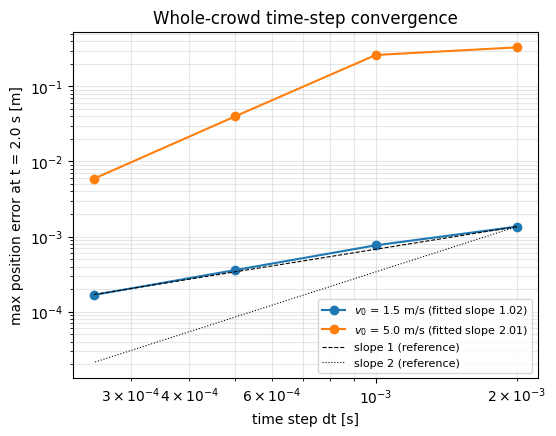

VERIFICATION: Trajectory error shrinks as dt shrinks (order reported, not assumed) -> PASS


In [59]:
# 4.9  Time-step study A: error of the whole-crowd trajectory against a very fine reference
# Compared over a SHORT horizon only: the dynamics are chaotic (cell 4.7), so any trajectory difference grows
# exponentially and a full evacuation cannot be compared run by run.
T_STUDY = 2.0                                  # [s]
DTS_A = np.array([0.002, 0.001, 0.0005, 0.00025])
DT_REF = 0.0000625
fig, ax = plt.subplots(figsize=(6, 4.5))
orders_A = {}
for v0_t in (1.5, 5.0):
    pos_t, rad_t = place_agents(PARAMS, np.random.default_rng(BASE_SEED))
    ref = run_evacuation(v0_t, BASE_SEED, dt=DT_REF, T_max=T_STUDY, use_cells=False, pos0=pos_t, rad=rad_t)['pos_end']
    errs = np.array([np.abs(run_evacuation(v0_t, BASE_SEED, dt=d, T_max=T_STUDY, use_cells=False, pos0=pos_t, rad=rad_t)['pos_end'] - ref).max()
                     for d in DTS_A])
    local = np.log(errs[:-1] / errs[1:]) / np.log(DTS_A[:-1] / DTS_A[1:])
    slope = np.polyfit(np.log(DTS_A), np.log(errs), 1)[0]
    orders_A[v0_t] = (errs, local, slope)
    print(f"v0 = {v0_t}: max position error [m] = " + ", ".join(f"{e:.1e}" for e in errs))
    print(f"        local orders = {np.round(local, 2)}, fitted slope = {slope:.2f}")
    ax.loglog(DTS_A, errs, 'o-', label=f'$v_0$ = {v0_t} m/s (fitted slope {slope:.2f})')
ax.loglog(DTS_A, orders_A[1.5][0][0] * (DTS_A / DTS_A[0]), 'k--', lw=0.8, label='slope 1 (reference)')
ax.loglog(DTS_A, orders_A[1.5][0][0] * (DTS_A / DTS_A[0]) ** 2, 'k:', lw=0.8, label='slope 2 (reference)')
ax.set_xlabel('time step dt [s]'); ax.set_ylabel(f'max position error at t = {T_STUDY} s [m]')
ax.set_title('Whole-crowd time-step convergence'); ax.legend(fontsize=8); ax.grid(True, which='both', alpha=0.3)
plt.show()
for v0_t, (errs, local, slope) in orders_A.items():
    assert errs[-1] < errs[0], f"The error does not shrink with the time step at v0 = {v0_t}!"
print("VERIFICATION: Trajectory error shrinks as dt shrinks (order reported, not assumed) -> PASS")

In [60]:
# 4.10  Time-step study B: does the quantity we care about (mean evacuation time) depend on dt?
STUDY_SEEDS = range(BASE_SEED, BASE_SEED + 6)      # raise to 12 for the final report (takes several minutes)
DTS_B = [0.002, 0.001, 0.0005]
rows_B = []
for v0_t in (1.5, 5.0):
    for d in DTS_B:
        r = replicate(v0_t, STUDY_SEEDS, dt=d)
        rows_B.append(r)
        print(f"v0 = {v0_t}, dt = {d}: mean = {r['mean']:6.1f} +/- {r['ci_half']:4.1f} s, valid {r['n_valid']}/{r['n_seeds']}")
# Statistical check: with the finest dt as reference, the difference of means should lie within the combined noise.
for v0_t in (1.5, 5.0):
    sub = [r for r in rows_B if r['v0'] == v0_t]
    ref_r = sub[-1]
    for r in sub[:-1]:
        se = np.sqrt(r['sd'] ** 2 / r['n_valid'] + ref_r['sd'] ** 2 / ref_r['n_valid'])
        print(f"   v0 = {v0_t}: dt = {r['dt']} vs {ref_r['dt']}: difference = {r['mean'] - ref_r['mean']:+.1f} s (std. error {se:.1f} s)")
        assert abs(r['mean'] - ref_r['mean']) < 3 * se, "Mean evacuation time still depends on dt!"
print("VERIFICATION: Mean evacuation time is insensitive to dt (within statistical noise) -> PASS")
# The time-step rule in dt_for_speed (0.001 s up to 5 m/s, 0.0005 s above) comes from this study plus the tunnelling at 10 m/s.
# Write the final choice and the reasoning in the markdown cell below this one.


v0 = 1.5, dt = 0.002: mean =   98.4 +/-  4.3 s, valid 6/6
v0 = 1.5, dt = 0.001: mean =  100.1 +/-  2.7 s, valid 6/6
v0 = 1.5, dt = 0.0005: mean =   98.7 +/-  3.1 s, valid 6/6
v0 = 5.0, dt = 0.002: mean =   67.9 +/-  7.3 s, valid 6/6
v0 = 5.0, dt = 0.001: mean =   69.9 +/-  7.2 s, valid 6/6
v0 = 5.0, dt = 0.0005: mean =   73.4 +/-  6.7 s, valid 6/6
   v0 = 1.5: dt = 0.002 vs 0.0005: difference = -0.2 s (std. error 2.1 s)
   v0 = 1.5: dt = 0.001 vs 0.0005: difference = +1.4 s (std. error 1.6 s)
   v0 = 5.0: dt = 0.002 vs 0.0005: difference = -5.5 s (std. error 3.9 s)
   v0 = 5.0: dt = 0.001 vs 0.0005: difference = -3.5 s (std. error 3.8 s)
VERIFICATION: Mean evacuation time is insensitive to dt (within statistical noise) -> PASS


In [61]:
#4.11  Verification of the pillar: analytic stand-off, a far-away pillar changes nothing, clear start, full evacuation
# (a) A single agent driven straight at a pillar must stop at: pillar centre distance = R + r + gap, gap = -B*ln(m*v0/(tau*A)).
R_p, r_a, v0_a, dt_a = 0.3, 0.30, 1.5, 0.001
gap_pred = -PARAMS['B'] * np.log(PARAMS['m'] * v0_a / (PARAMS['tau'] * PARAMS['A']))
x_a = np.array([2.0, 5.0]); v_a = np.zeros(2); e_a = np.array([1.0, 0.0])
pill_a = np.array([[5.0, 5.0, R_p]])
def acc_a(x, v):
    fx, fy = circle_force_fast(x[0], x[1], v[0], v[1], r_a, pill_a[0, 0], pill_a[0, 1], pill_a[0, 2],
                               PARAMS['A'], PARAMS['B'], PARAMS['k'], PARAMS['kappa'])
    return (PARAMS['m'] * (v0_a * e_a - v) / PARAMS['tau'] + np.array([fx, fy])) / PARAMS['m']
a_ = acc_a(x_a, v_a)
for _ in range(int(30.0 / dt_a)):
    x_new = x_a + v_a * dt_a + 0.5 * a_ * dt_a ** 2
    a_new = acc_a(x_new, v_a + a_ * dt_a)
    v_a = v_a + 0.5 * (a_ + a_new) * dt_a
    x_a, a_ = x_new, a_new
dist_sim = 5.0 - x_a[0]
dist_pred = R_p + r_a + gap_pred
print(f"stand-off from the pillar centre: simulated {dist_sim:.4f} m, predicted {dist_pred:.4f} m")
assert abs(dist_sim - dist_pred) < 1e-3, "Pillar stand-off distance does not match the analytic prediction!"

# (b) Limiting case: a pillar far outside the room cannot change anything, so the results must be identical
far = np.array([[EXIT_X, -10.0, 0.3]])
t_none = replicate(3.0, [BASE_SEED, BASE_SEED + 1], parallel=False)['times']
t_far = replicate(3.0, [BASE_SEED, BASE_SEED + 1], parallel=False, obst=far)['times']
print("no pillar:", np.round(t_none, 3), " far pillar:", np.round(t_far, 3))
assert np.allclose(t_none, t_far, equal_nan=True), "A pillar outside the room changed the result!"

# (c) The pillar must not overlap any starting position, and the evacuation must still be complete and conserving
pos_o, rad_o = place_agents(PARAMS, np.random.default_rng(BASE_SEED))
gap_min = np.linalg.norm(pos_o - pillar_default[0, :2], axis=1).min() - pillar_default[0, 2] - rad_o.max()
assert gap_min > 0.0, "The pillar overlaps the seating area!"
res_p = run_evacuation(1.5, BASE_SEED, use_cells=False, obst=pillar_default)
print(f"with pillar: out {res_p['n_out']}/150, evacuation time {res_p['evac_time']:.1f} s, conserved {res_p['conserved']}")
assert res_p['conserved'] and res_p['n_out'] == 150 and res_p['tunnelled'] == 0, "Evacuation with the pillar is broken!"
print("VERIFICATION: Pillar stand-off, far pillar changes nothing, clear start, complete evacuation -> PASS")


stand-off from the pillar centre: simulated 0.7696 m, predicted 0.7696 m
no pillar: [66.453 65.058]  far pillar: [66.453 65.058]
with pillar: out 150/150, evacuation time 104.8 s, conserved True
VERIFICATION: Pillar stand-off, far pillar changes nothing, clear start, complete evacuation -> PASS


## 5. Experiments and results



v0 =  1.0 m/s (dt = 0.001): mean =  151.4 +/-  5.7 s (95% CI), valid 6/6, 54.5 s
v0 =  1.5 m/s (dt = 0.001): mean =  100.1 +/-  2.7 s (95% CI), valid 6/6, 35.4 s
v0 =  2.0 m/s (dt = 0.001): mean =   77.8 +/-  3.2 s (95% CI), valid 6/6, 27.2 s
v0 =  3.0 m/s (dt = 0.001): mean =   63.1 +/-  2.7 s (95% CI), valid 6/6, 24.1 s
v0 =  4.0 m/s (dt = 0.001): mean =   66.6 +/-  2.8 s (95% CI), valid 6/6, 25.7 s
v0 =  5.0 m/s (dt = 0.001): mean =   69.9 +/-  7.2 s (95% CI), valid 6/6, 33.8 s
v0 =  7.0 m/s (dt = 0.0005): mean =   82.0 +/-  8.9 s (95% CI), valid 6/6, 65.2 s
v0 = 10.0 m/s (dt = 0.0005): mean =   84.9 +/-  8.6 s (95% CI), valid 6/6, 68.5 s
pilot sweep took 334 s


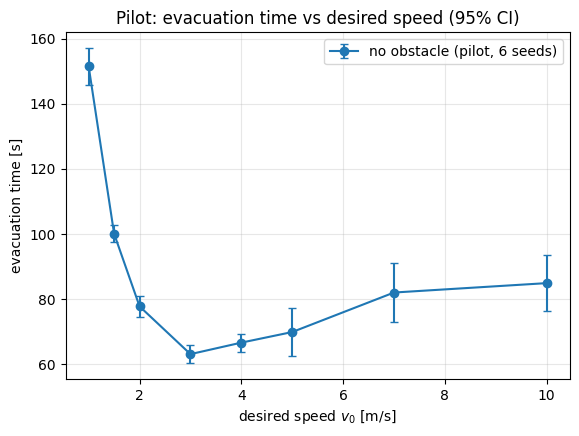

fastest evacuation at v0 = 3.0 m/s (63.1 s); at 10.0 m/s: 84.9 s


In [62]:
# 5.1  Pilot sweep (groundwork for the main experiment): evacuation time against desired speed
PILOT_SPEEDS = [1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 7.0, 10.0]
PILOT_SEEDS = range(BASE_SEED, BASE_SEED + 6)       # few seeds for the pilot; the main sweep uses 20
t_pilot = time.perf_counter()
pilot = sweep(PILOT_SPEEDS, PILOT_SEEDS)
print(f"pilot sweep took {time.perf_counter() - t_pilot:.0f} s")
fig, ax = plt.subplots(figsize=(6.5, 4.5))
plot_sweep(pilot, 'no obstacle (pilot, 6 seeds)', ax=ax)
ax.set_title('Pilot: evacuation time vs desired speed (95% CI)'); ax.legend()
plt.show()
means = np.array([r['mean'] for r in pilot])
i_min = int(np.nanargmin(means))
print(f"fastest evacuation at v0 = {PILOT_SPEEDS[i_min]} m/s ({means[i_min]:.1f} s); at {PILOT_SPEEDS[-1]} m/s: {means[-1]:.1f} s")


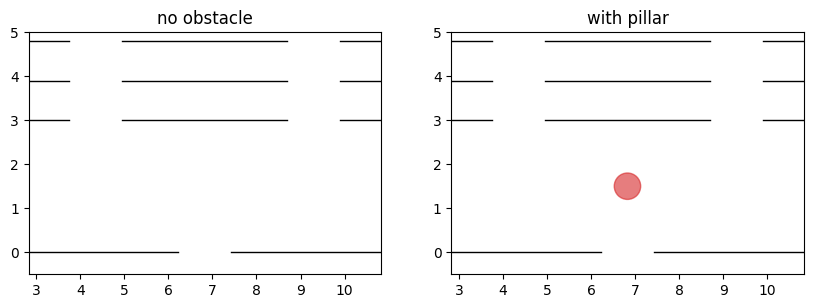

In [63]:
# 5.2  Door obstacle: one circular pillar in front of the exit (exact circle, see 3.6c, 3.9 and the check in 4.11)
pillar = make_pillar()                  # one row: centre x, centre y, radius [m]
px, py, R_p = pillar[0]

# nobody may start inside or touching the pillar
assert np.min(np.hypot(pos_demo[:, 0] - px, pos_demo[:, 1] - py)) > R_p + PARAMS['r_max']

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, ttl, show in zip(axs, ['no obstacle', 'with pillar'], [False, True]):
    for s in walls:
        ax.plot([s[0], s[2]], [s[1], s[3]], 'k-', lw=1)
    if show:
        ax.add_patch(plt.Circle((px, py), R_p, color='tab:red', alpha=0.6))
    ax.set_xlim(EXIT_X - 4, EXIT_X + 4); ax.set_ylim(-0.5, 5); ax.set_aspect('equal'); ax.set_title(ttl)
plt.show()

In [64]:
# 5.3  Replication for a modified configuration (exit width, force-law parameters); same machinery as 3.8
def replicate_cfg(v0, seeds, exit_width=None, overrides=None, obst=None, dt=None, T_max=400.0, level=0.95):
    """Like replicate() in 3.8, but with a different exit width [m] and/or different PARAMS entries
    (overrides, e.g. {'kappa': 0.0}). The same seeds give the same seat offsets and radii, so results pair with the baseline."""
    dt = dt_for_speed(v0) if dt is None else dt
    obst = NO_OBST if obst is None else obst
    pr = dict(PARAMS)
    if exit_width is not None:
        pr['exit_width'] = exit_width
    if overrides:
        pr.update(overrides)
    walls_use, _ = build_room_geometry(pr)
    P_use = np.array([pr['m'], pr['tau'], pr['A'], pr['B'], pr['k'], pr['kappa'], D_CUT, WALL_CUT])
    seeds = list(seeds)
    pos_all = np.empty((len(seeds), len(pos_demo), 2)); rad_all = np.empty((len(seeds), len(pos_demo)))
    for j, s in enumerate(seeds):
        pos_all[j], rad_all[j] = place_agents(pr, np.random.default_rng(s))
    evac, n_out, cons, tun = run_batch_core(pos_all, rad_all, v0, dt, T_max, walls_use, obst, AISLE_XC, GEO, P_use,
                                            NX, NY, ROOM_W, ROOM_L)
    valid = evac[np.isfinite(evac)]
    mean, half = mean_ci(valid, level)
    return dict(v0=v0, dt=dt, n_seeds=len(seeds), n_valid=len(valid), n_failed=len(seeds) - len(valid),
                mean=mean, ci_half=half, sd=float(valid.std(ddof=1)) if len(valid) > 1 else np.nan, times=evac)

def subset_row(rows, v0, n):
    """First n seeds of a finished sweep row at speed v0, so the baseline need not be recomputed."""
    r = next(x for x in rows if x['v0'] == v0)
    t = r['times'][:n]
    v = t[np.isfinite(t)]
    m, h = mean_ci(v)
    return dict(v0=v0, mean=m, ci_half=h, n_valid=len(v), n_seeds=n, times=t)

def paired_diff(t_a, t_b, level=0.95):
    """Mean of (a - b) over seeds where both runs succeeded, with a t-interval. Returns mean, half-width, number of pairs."""
    d = np.asarray(t_a, float) - np.asarray(t_b, float)
    d = d[np.isfinite(d)]
    m, h = mean_ci(d, level)
    return m, h, len(d)

def verdict(m, h):
    return 'clear' if (np.isfinite(h) and abs(m) > h) else 'not clear'

# checks: (a) no changes -> must reproduce replicate() exactly, (b) exit_width really sets the door gap
chk_a = replicate(3.0, [BASE_SEED, BASE_SEED + 1])['times']
chk_b = replicate_cfg(3.0, [BASE_SEED, BASE_SEED + 1])['times']
assert np.allclose(chk_a, chk_b, equal_nan=True), "replicate_cfg without changes differs from replicate!"
w2, _ = build_room_geometry({**PARAMS, 'exit_width': 2.0})
assert abs((w2[4, 0] - w2[3, 2]) - 2.0) < 1e-9, "exit width not applied to the geometry!"
print("VERIFICATION: replicate_cfg reproduces replicate; exit width sets the gap -> PASS")

VERIFICATION: replicate_cfg reproduces replicate; exit width sets the gap -> PASS


In [65]:
# 5.4  Main experiment: evacuation time vs desired speed, with and without the circular pillar
SPEEDS_MAIN = [1.5, 2.0, 3.0, 4.0, 5.0, 7.0]
SEEDS_MAIN = range(BASE_SEED, BASE_SEED + 10)     # same seeds for both curves (same seat offsets and body radii)

t_all = time.perf_counter()
if 'rows_none' not in globals():     # the baseline is unaffected by the pillar fix, so reuse it if already computed this session
    print('--- no obstacle ---')
    rows_none = sweep(SPEEDS_MAIN, SEEDS_MAIN)
print('--- circular pillar ---')
rows_obs = sweep(SPEEDS_MAIN, SEEDS_MAIN, obst=pillar)
print(f"main sweeps took {time.perf_counter() - t_all:.0f} s")

--- circular pillar ---
v0 =  1.5 m/s (dt = 0.001): mean =  104.0 +/-  1.7 s (95% CI), valid 10/10, 64.2 s
v0 =  2.0 m/s (dt = 0.001): mean =   82.3 +/-  1.7 s (95% CI), valid 10/10, 50.8 s
v0 =  3.0 m/s (dt = 0.001): mean =   68.5 +/-  2.5 s (95% CI), valid 10/10, 43.2 s
v0 =  4.0 m/s (dt = 0.001): mean =   73.2 +/-  3.5 s (95% CI), valid 10/10, 47.5 s
v0 =  5.0 m/s (dt = 0.001): mean =   71.0 +/-  3.1 s (95% CI), valid 10/10, 46.5 s
v0 =  7.0 m/s (dt = 0.0005): mean =   75.8 +/-  3.2 s (95% CI), valid 10/10, 101.6 s
main sweeps took 354 s


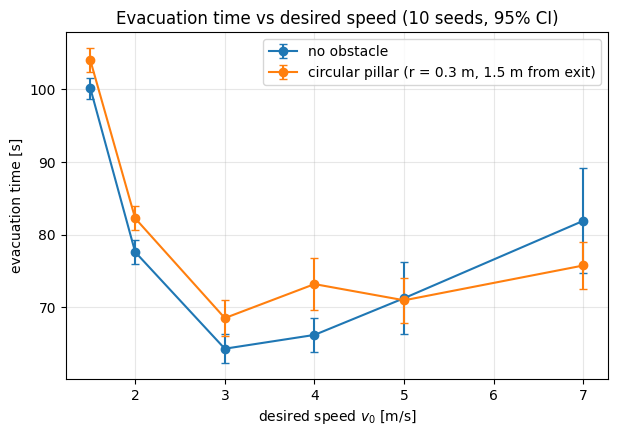

no obstacle: fastest at v0 = 3.0 m/s (64.3 s); at 7.0 m/s: 81.9 s (difference +17.6 s, std. error 3.3 s)
pillar: fastest at v0 = 3.0 m/s (68.5 s); at 7.0 m/s: 75.8 s (difference +7.2 s, std. error 1.8 s)

pillar minus no obstacle, paired by seed:
v0 =  1.5:   +3.8 +/-  1.8 s (10 paired seeds) -> pillar slower
v0 =  2.0:   +4.6 +/-  2.3 s (10 paired seeds) -> pillar slower
v0 =  3.0:   +4.2 +/-  3.5 s (10 paired seeds) -> pillar slower
v0 =  4.0:   +7.0 +/-  4.5 s (10 paired seeds) -> pillar slower
v0 =  5.0:   -0.3 +/-  4.9 s (10 paired seeds) -> no clear difference
v0 =  7.0:   -6.2 +/-  7.8 s (10 paired seeds) -> no clear difference


In [66]:
# 5.5  Results: curves with 95% CIs, minimum, faster-is-slower check, paired obstacle comparison
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_sweep(rows_none, 'no obstacle', ax=ax)
plot_sweep(rows_obs, f"circular pillar (r = {PARAMS['obstacle_radius']} m, {PARAMS['obstacle_dist']} m from exit)", ax=ax)
ax.set_title(f'Evacuation time vs desired speed ({len(SEEDS_MAIN)} seeds, 95% CI)'); ax.legend()
plt.show()

for name, rows in (('no obstacle', rows_none), ('pillar', rows_obs)):
    means = np.array([r['mean'] for r in rows]); i = int(np.nanargmin(means))
    r_hi = rows[-1]
    se = np.sqrt(rows[i]['sd'] ** 2 / rows[i]['n_valid'] + r_hi['sd'] ** 2 / r_hi['n_valid'])
    print(f"{name}: fastest at v0 = {rows[i]['v0']} m/s ({means[i]:.1f} s); at {r_hi['v0']} m/s: {r_hi['mean']:.1f} s "
          f"(difference {r_hi['mean'] - means[i]:+.1f} s, std. error {se:.1f} s)")

print("\npillar minus no obstacle, paired by seed:")
for rn, ro in zip(rows_none, rows_obs):
    d = ro['times'] - rn['times']
    d = d[np.isfinite(d)]
    m, h = mean_ci(d)
    txt = 'pillar faster' if m + h < 0 else ('pillar slower' if m - h > 0 else 'no clear difference')   # 'txt', not 'verdict': verdict() is a function (5.3)
    print(f"v0 = {rn['v0']:4.1f}: {m:+6.1f} +/- {h:4.1f} s ({len(d)} paired seeds) -> {txt}")

table = np.array([[a['v0'], a['mean'], a['ci_half'], b['mean'], b['ci_half']] for a, b in zip(rows_none, rows_obs)])
np.savetxt('sweep_results.csv', table, delimiter=',', header='v0,mean_none,ci_none,mean_pillar,ci_pillar', comments='')

In [67]:
# 5.6  kappa = 0: is sliding friction what makes fast crowds slow?  (the body force k stays on)
SPEEDS_W = [3.0, 7.0]
SEEDS_W = list(range(BASE_SEED, BASE_SEED + 6))
n_w = len(SEEDS_W); lo, hi = SPEEDS_W[0], SPEEDS_W[-1]
KAPPAS = [0.0]                         # sliding-friction constant [kg/(m s)]; the baseline 2.4e5 comes from the main sweep

res_k = {}
t_k = time.perf_counter()
for kap in KAPPAS:
    for v0 in SPEEDS_W:
        t0 = time.perf_counter()
        r = res_k[(kap, v0)] = replicate_cfg(v0, SEEDS_W, overrides={'kappa': kap})
        print(f"kappa = {kap:g}, v0 = {v0} m/s: mean = {r['mean']:6.1f} +/- {r['ci_half']:4.1f} s, "
              f"valid {r['n_valid']}/{n_w}, {time.perf_counter() - t0:.0f} s")
print(f"kappa study took {time.perf_counter() - t_k:.0f} s")

base_k = {v0: subset_row(rows_none, v0, n_w) for v0 in SPEEDS_W}
print(f"\nbaseline (kappa = {PARAMS['kappa']:g}): " + ", ".join(f"{v0} m/s: {base_k[v0]['mean']:.1f} s" for v0 in SPEEDS_W))
m_b, h_b, n_b = paired_diff(base_k[hi]['times'], base_k[lo]['times'])
print(f"baseline penalty ({hi} minus {lo} m/s): {m_b:+.1f} +/- {h_b:.1f} s ({n_b} pairs) -> {verdict(m_b, h_b)}")
for kap in KAPPAS:
    for v0 in SPEEDS_W:
        m, h, n = paired_diff(res_k[(kap, v0)]['times'], base_k[v0]['times'])
        print(f"kappa = {kap:g} minus baseline at {v0} m/s: {m:+6.1f} +/- {h:4.1f} s ({n} pairs) -> {verdict(m, h)}")
    m, h, n = paired_diff(res_k[(kap, hi)]['times'], res_k[(kap, lo)]['times'])
    print(f"kappa = {kap:g} penalty ({hi} minus {lo} m/s): {m:+.1f} +/- {h:.1f} s ({n} pairs) -> {verdict(m, h)}")

kappa = 0, v0 = 3.0 m/s: mean =   49.9 +/-  1.4 s, valid 6/6, 17 s
kappa = 0, v0 = 7.0 m/s: mean =   24.6 +/-  0.7 s, valid 6/6, 19 s
kappa study took 36 s

baseline (kappa = 240000): 3.0 m/s: 63.1 s, 7.0 m/s: 82.0 s
baseline penalty (7.0 minus 3.0 m/s): +18.9 +/- 8.4 s (6 pairs) -> clear
kappa = 0 minus baseline at 3.0 m/s:  -13.3 +/-  3.2 s (6 pairs) -> clear
kappa = 0 minus baseline at 7.0 m/s:  -57.4 +/-  9.3 s (6 pairs) -> clear
kappa = 0 penalty (7.0 minus 3.0 m/s): -25.3 +/- 1.9 s (6 pairs) -> clear


exit width x0.8: change  +47.5 +/-  6.4 s (+75.3% of baseline), 6 pairs -> clear
exit width x1.2: change  -16.8 +/-  3.3 s (-26.6% of baseline), 6 pairs -> clear
kappa      x0.8: change   -1.8 +/-  4.4 s ( -2.8% of baseline), 6 pairs -> not clear
kappa      x1.2: change   +3.9 +/-  3.2 s ( +6.3% of baseline), 6 pairs -> clear
tau        x0.8: change   +1.8 +/-  5.9 s ( +2.9% of baseline), 6 pairs -> not clear
tau        x1.2: change   +3.8 +/-  2.1 s ( +6.0% of baseline), 6 pairs -> clear
A          x0.8: change  +12.2 +/-  3.5 s (+19.4% of baseline), 6 pairs -> clear
A          x1.2: change   -2.3 +/-  3.0 s ( -3.6% of baseline), 6 pairs -> not clear
B          x0.8: change   +0.0 +/-  5.9 s ( +0.1% of baseline), 6 pairs -> not clear
B          x1.2: change   +0.4 +/-  4.4 s ( +0.7% of baseline), 6 pairs -> not clear
k          x0.8: change   +3.6 +/-  2.7 s ( +5.7% of baseline), 6 pairs -> clear
k          x1.2: change   -1.0 +/-  4.0 s ( -1.5% of baseline), 6 pairs -> not clear
sens

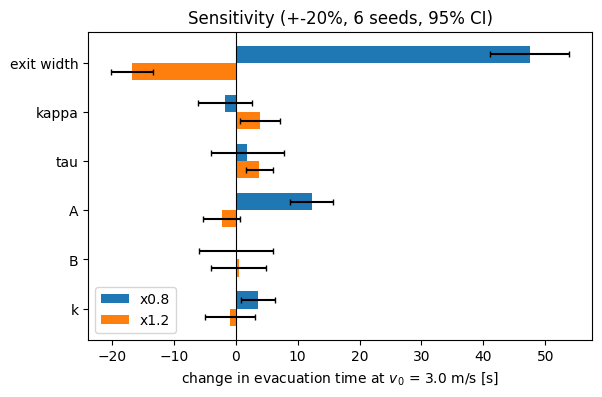

In [68]:
# 5.7  One-at-a-time sensitivity: which inputs drive the evacuation time? (+-20% on each, same seeds, paired)
V0_SENS = 3.0      # desired speed [m/s]. 3 m/s is cheap and has the tightest intervals; 7.0 would be about 3x slower
SEEDS_S = list(range(BASE_SEED, BASE_SEED + 6))
FACTORS = (0.8, 1.2)
INPUTS = {
    'exit width': lambda f: dict(exit_width=PARAMS['exit_width'] * f),
    'kappa':      lambda f: dict(overrides={'kappa': PARAMS['kappa'] * f}),
    'tau':        lambda f: dict(overrides={'tau': PARAMS['tau'] * f}),
    'A':          lambda f: dict(overrides={'A': PARAMS['A'] * f}),
    'B':          lambda f: dict(overrides={'B': PARAMS['B'] * f}),
    'k':          lambda f: dict(overrides={'k': PARAMS['k'] * f}),
}
base_s = subset_row(rows_none, V0_SENS, len(SEEDS_S))
sens = {}
t_s = time.perf_counter()
for name, make in INPUTS.items():
    for f in FACTORS:
        r = replicate_cfg(V0_SENS, SEEDS_S, **make(f))
        m, h, n = paired_diff(r['times'], base_s['times'])
        sens[(name, f)] = (m, h, n)
        print(f"{name:10s} x{f:.1f}: change {m:+6.1f} +/- {h:4.1f} s ({100 * m / base_s['mean']:+5.1f}% of baseline), "
              f"{n} pairs -> {verdict(m, h)}")
print(f"sensitivity study took {time.perf_counter() - t_s:.0f} s")

fig, ax = plt.subplots(figsize=(6.5, 4))
y = np.arange(len(INPUTS))
for j, f in enumerate(FACTORS):
    ms = [sens[(nm, f)][0] for nm in INPUTS]; hs = [sens[(nm, f)][1] for nm in INPUTS]
    ax.barh(y + (j - 0.5) * 0.35, ms, height=0.35, xerr=hs, capsize=2, label=f'x{f}')
ax.set_yticks(y); ax.set_yticklabels(list(INPUTS)); ax.axvline(0, color='k', lw=0.8); ax.invert_yaxis()
ax.set_xlabel(f'change in evacuation time at $v_0$ = {V0_SENS} m/s [s]'); ax.legend()
ax.set_title('Sensitivity (+-20%, 6 seeds, 95% CI)')
plt.show()

## 6. Discussion and limitations

To be completed.

**Web demo reference value:** with default settings the web demo should reproduce [value ± tolerance] from section [N].

## 7. References

To be completed.